# W10A · A · LoRA·양자화·QLoRA 해부

2026-11-02 · 주교재6.4–6.9 · 패키지0.1.16

같은 base 모델에서 작은 어댑터만 실제 SFT 학습하고, 고정 가중치·응답 정답·저장 표현을 확인합니다. 몇 회의 갱신은 일반 지시 이행 성능 보장이 아닙니다.

Drive에 새 사본을 저장하고 첫 셀부터 독립 실행하세요. 이전 차시·다른 노트북의 변수·파일·어댑터가 필요하지 않습니다. API키·개인 파일 업로드·유료 GPU는 필수가 아닙니다. 설치·모델 준비 실패를 가짜 결과로 대체하지 않습니다.

**예측 → 최소 실행/중간값 → 한 조건 변경 → 근거와 한계 → 새 사례 설명** 순서로 기록합니다. `my_...=None`은 독립 연습 변수이며 기본 실행을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/course/notion/w10a/w10a-lesson.md) · [기록지/점검](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/course/notion/w10a/w10a-workbook.md) · [API와 실제 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/src/W10A-API.md)

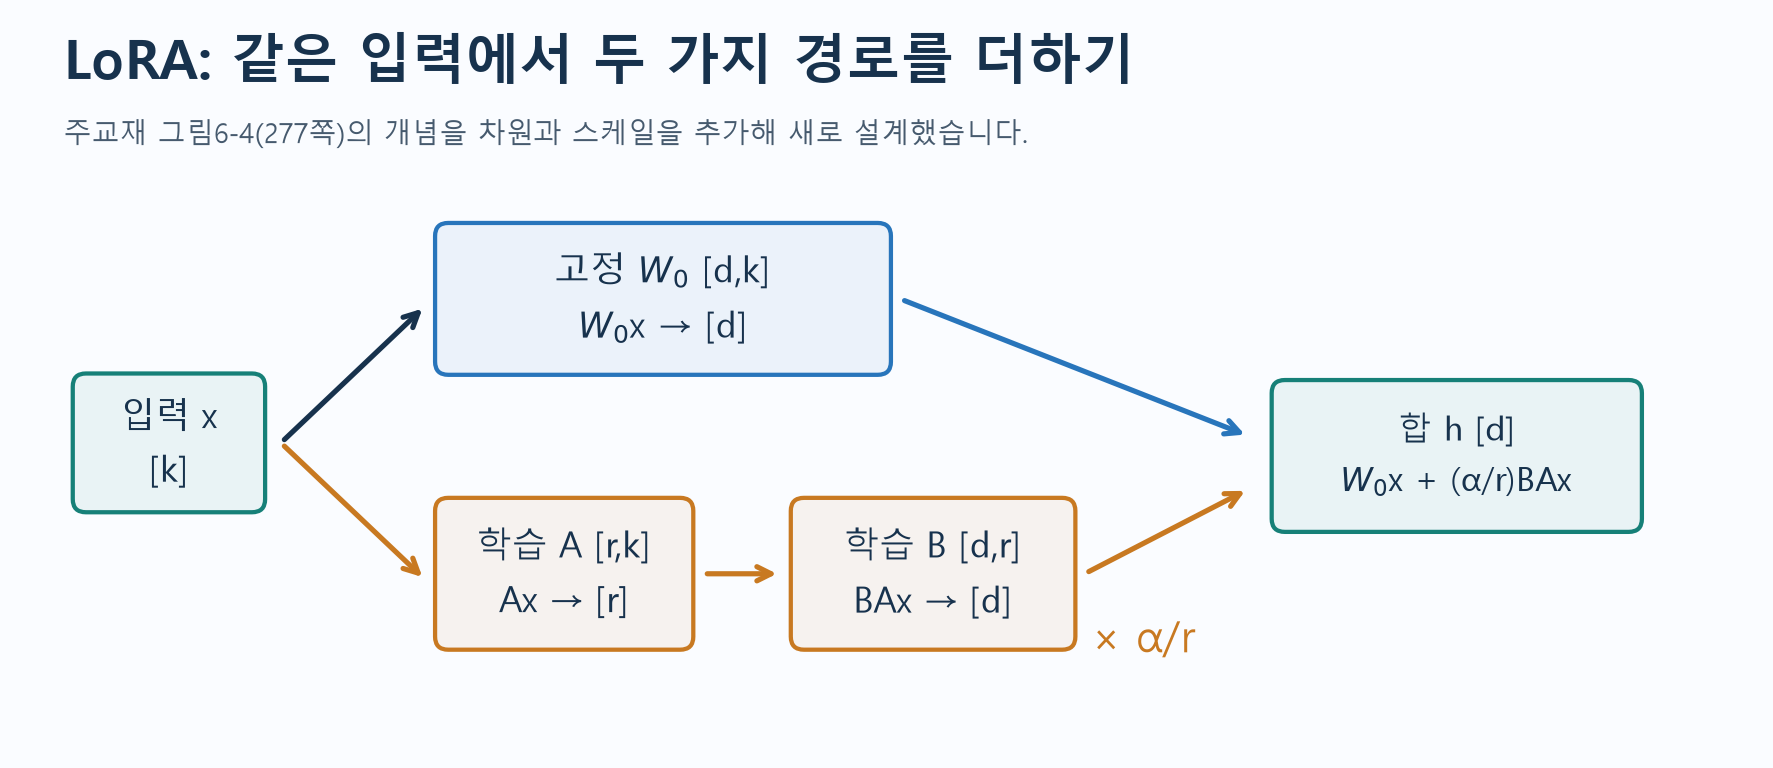

## 준비

CPU 필수 경로의 작은 모델을 자동 준비합니다. A의 base 모델 선택 파일 약541MB, B의 Instruct+임베딩 약363MB 외에 의존성 설치가 필요합니다. 완전한 캐시는 재사용합니다. Python3.12/3.13 지원을 검증하며 이미 다른 버전을 import했다면 런타임을 재시작합니다. `prepare_text_runtime()`은 새 자식 Python에서 import를 검사하고, 실제 실패한 선택 영상/음성 패키지만 복구합니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w10a/course/notion/w10a/assets/02-lora-shapes.png)


In [ ]:
import sys,subprocess,os,json,time,uuid,math
from pathlib import Path
from importlib.metadata import version,PackageNotFoundError
PUBLIC_REF='2026-fall-w10a'
try: ready=all(version(p)==v for p,v in [('luna-genai','0.1.16'),('transformers','5.15.1'),('gradio','6.26.0'),('peft','0.21.2'),('trl','1.17.1'),('accelerate','1.15.0'),('bitsandbytes','0.50.2')])
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules:
        raise RuntimeError('이전 버전을 불러온 상태입니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
    if Path('src/pyproject.toml').exists():
        package=str(Path('src').resolve())+"[adaptation]"
        subprocess.run([sys.executable,'-m','pip','install','-q','-e',package],check=True)
    else:
        package="luna-genai[adaptation] @ "+f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
        subprocess.run([sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed=prepare_text_runtime(repair_optional=True)
import torch,numpy as np,pandas as pd
from IPython.display import display
torch.set_num_threads(2)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
print('Python',sys.version.split()[0],'package',version('luna-genai'),'CPU 기본','CUDA available',torch.cuda.is_available())
print('실제로 복구한 비호환 선택 패키지:',removed)
RUN_ID=uuid.uuid4().hex[:8]


In [ ]:
from luna_genai.peft_lab import AdapterLab,load_headline_data,response_batch,parameter_digest
from luna_genai.finetuning import target_table
from luna_genai.quantization import absmax_quantize,lora_dimensions,weight_storage
from luna_genai.peft_app import build_adapter_app,adapter_view,quantization_view,observation_note
data=load_headline_data()
display(pd.DataFrame([{'split':s,'source_documents':len(data[s])} for s in ('train','validation','test')]))
print(data['provenance'])
lab=AdapterLab(device='cpu',rank=4,alpha=8,max_length=64,seed=42)
display(lab.state())


## 1. 작은 수계산에서 실제 모수 수로

고정 $W_0\in\mathbb{R}^{d\times k}$와 학습 $A\in\mathbb{R}^{r\times k}$, $B\in\mathbb{R}^{d\times r}$를 씁니다.

$$
h=W_0x+\frac{\alpha}{r}BAx
$$

한 선택 층에서 전체 $dk$개 대신 $r(d+k)$개를 학습합니다. 작은 행렬은 차원 이해용이고 큰 축소는 큰 층에서 확인합니다. 아래는 완성 계산 예제이며 A1은 다른 숫자입니다.


In [ ]:
W0=np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0.]])
A_demo=np.array([[1.,0,1,-1]]);B_demo=np.array([[1.],[-2.],[.5]]);x=np.array([1.,2.,0.,-1.])
print('W0x:',W0@x,'Ax:',A_demo@x,'BAx:',B_demo@A_demo@x,'h:',W0@x+2*(B_demo@A_demo@x))
display(pd.DataFrame([lora_dimensions(3,4,1),lora_dimensions(4096,4096,8)]))
my_h=None
my_count=None


### A1 · 필수 · 차원/모수 수계산

$W_0=I_2$, $x=(1,-1)^T$, $A=(2,1)$, $B=(1,3)^T$, $r=1$, $\alpha=2$에서 $Ax$, 업데이트와 $h$를 손으로 구하세요. 이 작은 층은 LoRA 학습 모수 수가 줄어드나요?

**힌트:** 먼저 각 곱의 shape를 적고 마지막에 두 경로를 더하세요.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 2. 응답 정답과 실제 짧은 SFT

원문24개를 train16/validation4/test4로 먼저 나눴습니다. `response_batch()`는 base 모델용 **사용자 정의 형식**의 지시·원문과 목표 헤드라인을 연결합니다. 고유 chat template이라고 부르지 않습니다. prompt/PAD는 labels=-100, 응답과 진짜 EOS는 정답입니다. labels를 여기서 한 칸 이동하지 않습니다.

`fit()`은 전처리한 labels를 TRL SFTTrainer에 전달하며 packing=False입니다. `completion_only_loss=False`여도 이미 labels에 응답 마스크를 명시했으므로 전체 prompt를 학습하는 것이 아닙니다. `assistant_only_loss=True`를 지원 여부 확인 없이 복사하지 않습니다.

기본 경로는 batch1·길이64·4회·초기 lr5e-4와 선형 lr 감소입니다. AdamW는 어댑터만 갱신합니다. 첫 A 기울기0과 B 기울기를 따로 관찰하세요. 기본 A는 랜덤/B는0이며 둘 다0으로 만들면 학습이 멈출 수 있습니다.


In [ ]:
batch=lab.batch(data['train'][:2])
display(target_table(batch,lab.tokenizer,row=0))
print('shape:',{k:tuple(v.shape) for k,v in batch.items()})
probe_text=data['test'][0]['input']
before=lab.evaluate(data['validation']);before_text=lab.generate(probe_text)
training=lab.fit(data['train'],steps=4,output_dir=f'.build/w10a-{RUN_ID}-sft')
after=lab.evaluate(data['validation']);after_text=lab.generate(probe_text)
display(pd.DataFrame([{'phase':'before',**before},{'phase':'after',**after}]))
display(pd.DataFrame(training['history']));display(pd.DataFrame(training['gradients']))
print('before:',before_text['text']);print('after:',after_text['text'])
print('전체 non-LoRA 파라미터 해시 동일:',training['base_unchanged'])
print('변한 어댑터 tensor 수:',sum(v>0 for v in training['adapter_l2_changes'].values()))
reload_check=lab.save_reload_check(f'.build/w10a-{RUN_ID}-adapter',data['validation'][0])
display(reload_check)
my_evidence=None


### A2 · 필수 · 실제 갱신의 증거

기본 모델과 어댑터 중 무엇이 변했는지 실행 결과로 설명하세요. 첫 A 기울기가0이면 학습 실패인가요? 출력 문장이 같아도 가중치 갱신이 있었을 수 있나요? 재로딩과 float 병합의 검사는 각각 무엇을 확인하나요?

**힌트:** 해시·requires_grad·A/B 기울기·변화량·logits 오차를 연결하세요.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 3. 양자화: 정수·복원값·오차를 한 줄씩

작은 NumPy 배열의 대칭 absmax 양자화입니다. `step=max(abs(x))/qmax`, `q=round(x/step)`, `복원=q*step`입니다. 반올림은 ties-to-even, 범위 밖은 clip합니다. **균등 정수 격자는 NF4가 아닙니다.** 반환 q는 관측용 int64 배열이므로 실제4bit로 압축 저장한 파일도 아닙니다.

FP16/BF16은 둘 다16bit지만 지수와 가수에 배분하는 비트가 다릅니다. BF16은 FP32와 비슷한 지수 범위지만 FP16보다 가수 정밀도가 낮습니다. dtype cast와 scale/codebook을 쓰는 양자화를 구별하세요.


In [ ]:
q4=absmax_quantize([-3.2,-.2,0,.7,3.5],4)
display(pd.DataFrame({k:q4[k] for k in ('input','q','restored','error')}));print('step',q4['step'],'MAE',q4['mae'])
ordinary=absmax_quantize([.1,.2,.3,1.],4)
outlier=absmax_quantize([.1,.2,.3,100.],4)
display(pd.DataFrame({'ordinary_restored':ordinary['restored'],'outlier_restored':outlier['restored']}))
display(pd.DataFrame([weight_storage(70_000_000_000,b) for b in (16,8,4)]))
my_quantization_explanation=None


### A3 · 필수 · 한 이상치 변경

위 두 배열에서 앞의 세 값은 같은데 복원값이 달라지는 이유를 설명하세요. bits만8로 바꾼 비교를 실행하고, 영벡터와 실제 메모리 해석의 함정도 기록하세요.

**힌트:** 이상치가 바꾸는 step, 작은 값의 반올림, 가중치만의 하한을 구별하세요.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 4. QLoRA 설정과 손실 마스크 읽기

4bit NF4 기본 가중치를 고정하고 LoRA만 학습합니다. double quant는 양자화 상수도 압축하는 기법입니다. 블록을 계산 dtype으로 복원하여 연산하므로 저장4bit·계산 dtype·어댑터 dtype은 서로 다릅니다.

구현 경로는 `BitsAndBytesConfig` → `prepare_model_for_kbit_training` → `LoraConfig/get_peft_model` → `SFTConfig/SFTTrainer`입니다. `target_modules=['q_proj','v_proj']`, r4/alpha8/dropout0/task_type=CAUSAL_LM을 씁니다. `all-linear`는 더 넓은 선형층을 선택하는 설정이고 DoRA의 `use_dora`는 방향/크기 분리 확장입니다. 이번 기본 실행에서 DoRA를 학습하지 않습니다.

아래 JSON은 **검증된 사전 실행 기록**입니다. 이 셀에서 QLoRA를 live 실행했다는 뜻이 아닙니다. Windows CPU의 실제270개4bit계층·4회학습·기본해시불변·어댑터갱신을 확인한 기록입니다. GPU/T4나7B 모델 검증으로 확대하지 않습니다. TRL1.17.1 초기화의 BF16 자동 cast 후 어댑터를 FP32로 유지하며, NF4 기본 계산 dtype은 CPU에서FP32입니다. CUDA 경로는 지원 시BF16, 미지원 시FP16을 선택하지만 실제 해당GPU 검증은 별도입니다.


In [ ]:
from importlib.resources import files
qlora_record=json.loads(files('luna_genai').joinpath('datasets/w10a-qlora-record.json').read_text(encoding='utf-8'))
print(qlora_record['kind']);display(qlora_record['state']);display(pd.DataFrame(qlora_record['history']))
RUN_REAL_4BIT=False  # 선택: 지원 장치의 실제 실행. 실패를 성공 기록으로 대체하지 않습니다.
my_mask_fix=None
learner_note=None


### A4 · 필수 · 디버깅/실행 모드/앱 연결

① labels[input_ids==pad_id]=-100으로 전부 지우는 오류 ② labels를 미리 한 칸 이동하는 오류를 고치세요. QLoRA에서는 어느 가중치가 고정되고 무엇이 학습되나요? 마지막 앱의 learner_note(prediction,observation,limitation)를 작성하고 위젯 순서와 함수 인자 순서를 설명하세요.

**힌트:** 진짜EOS와PAD의 역할은 위치 마스크로 구별합니다. 앱은 같은lab을 재사용하고 설명 함수만 따로 연결합니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


### X1 · 확장 · rank/scale 통제

r=2와4를 비교하는 실험을 설계하세요. alpha/r를 고정하지 않으면 무엇이 섞이나요? 학습과 평가 조건을 고정하여 작은 실제 비교를 실행하세요.

**힌트:** 매번 새 같은 base/seed에서 시작하고 alpha=2*r로 둡니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


### X2 · 확장 · 실제4bit 추가 실행

선택 경로를 실행할 때 live 성공이라고 부르기 위한 조건과 지원 장치/버전 기록을 정리하세요. 지원되지 않는 장치에서 나온 오류를 어떻게 보고해야 하나요?

**힌트:** 실제4bit계층·학습대상·loss·기울기·변화량을 확인합니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


In [ ]:
live_qlora=None
if RUN_REAL_4BIT:
    qlab=AdapterLab(device='cpu',quantized=True,rank=4,alpha=8,max_length=64)
    live_qlora=qlab.fit(data['train'],steps=4,output_dir=f'.build/w10a-{RUN_ID}-nf4')
    print('실제 이 런타임의4bit학습:',qlab.state());display(pd.DataFrame(live_qlora['history']))
    assert qlab.state()['quantized_4bit_layers']>0 and qlab.state()['trainable_base']==0
    assert live_qlora['base_unchanged'] and any(v>0 for v in live_qlora['adapter_l2_changes'].values())
    del qlab
else:
    print('live4bit 미실행: 위 사전 검증 기록 분석 모드입니다. 필수 float LoRA는 실제 실행했습니다.')


## 5. 마지막 웹앱과 독립 검증

앱의 실제 모델 비교·수치 격자·설명 함수를 조작합니다. 클릭으로 모델을 다시 받거나 학습하지 않습니다. 수치 격자 탭은 교육용 배열이고 실제 모델NF4 탭이라고 부르지 않습니다. Colab 공유 URL은 현재 런타임 동안 유지됩니다. 인라인JavaScript 오류가 나면 새 셀에서 `print(app.share_url)`을 실행해 주소를 새 탭에서 여세요.


In [ ]:
app=build_adapter_app(lab,note_fn=learner_note)
app.launch(share=IN_COLAB,prevent_thread_lock=True,quiet=True)
print('앱 주소:',app.share_url if IN_COLAB else app.local_url)


In [ ]:
assert lab.state()['trainable_base']==0 and lab.state()['trainable_adapter']==230400
assert training['base_digest_before']==training['base_digest_after']
assert any(v>0 for v in training['adapter_l2_changes'].values()) and reload_check['passed'] and reload_check['merge']['passed']
assert (batch['labels'][batch['attention_mask']==0]==-100).all()
assert np.isfinite([r['loss'] for r in training['history']]).all()
table,qstate=quantization_view('-3.2,-0.2,0,0.7,3.5',4)
assert len(table)==5 and qstate['step']==.5
base_view,adapted_view,app_record=adapter_view(lab,data['test'][0]['input'])
assert app_record['adapted']['state']['steps']==4 and app_record['adapted']['new_token_ids']
assert qlora_record['base_unchanged'] and qlora_record['adapter_changed']
print('W10A_A_RUNTIME_PASS · 실제 float LoRA/마스크/저장·재로딩/병합/수계산/callback 통과')
print('4bit 모드:', '실제 현재 런타임 실행' if live_qlora else '사전 검증 기록 분석')
if not IN_COLAB:app.close()
